# Feature selection, steps 1–3: which inputs earn their place?

The tuned model (`06_lgbm_tuning.ipynb`, plus the 4-week windows adopted on 26 Oct 2026) reads **38 inputs**: the 28
weekly store features, the 8 adopted 4-week features, `weeks_since_open` and the application score. Some of them may
add nothing: near-copies of each other, or features the model never relies on. A smaller set is easier to explain in
the report, less likely to fit noise, and cheaper to score.

This notebook gathers the evidence. It **does not change the model's inputs**: dropping features is a team decision,
made with the refit trials it points to at the end (`python -m models.feature_lab --drop ... --together`).

| § | What | Question |
|---|---|---|
| 0 | Setup | |
| 1 | The table | same rows, folds and application score as the feature lab |
| 2 | Inventory | how much signal does each feature carry on its own? |
| 3 | Near-duplicates | which features are almost copies of each other? |
| 4 | What the model relies on | how much does the tuning measure fall when a feature (or its copies) is shuffled? |
| 5 | Summary | a provisional label per feature and per family |
| 6 | Next step and report | which families to try dropping |

**Rules kept.** Training months 0–4 only, the baseline's three folds (train 0–1 → validate 2, 0–2 → 3, 0–3 → 4);
month 5 and test months 6–7 are never read. Labels only through `amldata`. The measure that decides is the team's
**weekly recall** (share of each week's mules in that week's top 1% of open accounts, mean over weeks 0–26; decision
26 Oct 2026).

## 0. Setup

In [1]:
from __future__ import annotations
import os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# find the repo root (the folder holding src/amldata) so Run All works from notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import lightgbm as lgb
from sklearn.metrics import roc_auc_score
import amldata
from features import candidates
from features.weekly import FEATURES as WEEKLY
from models import feature_lab as lab
from models import feature_selection as fs
from models.lgbm_baseline import FOLDS, KEY, load_table, profiles

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)     # data/v1_full by default; data/v1 for a quick run
RUN = os.path.basename(os.path.normpath(OUT))
REPORT = Path(os.environ.get("EDA_REPORT", "outputs/modelling/feature_selection" + ("" if RUN == "v1_full" else f"/{RUN}")))
REPORT.mkdir(parents=True, exist_ok=True)
MONTHS = (0, 1, 2, 3, 4)
WEEKS = (0, 26)          # main horizon, weeks since opening
SEED = 42
COLS = fs.ALL_INPUTS     # the tuned model's 38 inputs, in the feature lab's order
CLUSTER_AT = 0.8         # assumption: |Spearman| >= 0.8 for every pair = near-duplicates (0.7 / 0.9 shown too)
REPEATS = 3              # shuffles per feature per fold
NEEDED = 0.005           # assumption: a shuffle that costs >= 0.5 points of weekly recall, in all 3 folds, counts
INK, MUTED, GRID, BLUE = "#0b0b0b", "#898781", "#e1e0d9", "#2a78d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.edgecolor": "#c3c2b7", "font.size": 10, "text.color": INK})
show = (lambda x: display(x)) if "ipykernel" in sys.modules else print
T0 = time.time()
print(f"data {OUT} -> report {REPORT} | lightgbm {lgb.__version__}")

data data/v1 -> report outputs\modelling\feature_selection\v1 | lightgbm 4.7.0


## 1. The table

Exactly the feature lab's table: one row per account per open week 0–26 (weeks after the bank closed an account are
dropped), the 28 store features, the 8 adopted 4-week features, `weeks_since_open`, and the label `mule_by_day`.
The **application score** is a logistic regression on the 56 prepared application columns, built per fold as in
notebook 06 (out of fold for training accounts). The raw application columns are not model inputs here, so they are
left out of the table to save memory.

In [2]:
df, _ = load_table(OUT, MONTHS, WEEKS, adopted=True)
df = df[KEY + ["open_month", "mule_by_day"] + WEEKLY + candidates.ADOPTED]
df = df.sort_values(KEY, kind="stable").reset_index(drop=True)
scores = lab.app_scores(OUT, SEED)               # per fold: account -> application score
prof = profiles(OUT, MONTHS)                     # hidden type, for breakdowns only
print(f"{len(df):,} account-weeks, {int(df['mule_by_day'].sum()):,} mule weeks ({df['mule_by_day'].mean():.3%}); "
      f"{df['account_id'].nunique():,} accounts; {len(COLS)} inputs in {len(fs.FAMILIES)} families "
      f"({time.time() - T0:.0f}s)")
show(pd.DataFrame({"features": [", ".join(c) for c in fs.FAMILIES.values()],
                   "n": [len(c) for c in fs.FAMILIES.values()]}, index=list(fs.FAMILIES)))

912,451 account-weeks, 1,819 mule weeks (0.199%); 33,801 accounts; 38 inputs in 10 families (13s)


,features,n
volume_wk,"n_rows_wk, n_in_wk, n_out_wk, money_in_wk, mon...",8
volume_cum,"n_rows_cum, money_in_cum, money_out_cum",3
counterparties,"n_payers_wk, n_payees_wk, new_payer_share_wk, ...",5
flow,"passthrough_wk, out_1h_share_wk, out_24h_share...",4
self_vs_past,"self_vs_past_money_in, self_vs_past_payers, se...",3
peer,peer_ratio_money_in,1
mix,"internal_out_share_cum, cash_in_share_cum, abr...",4
window_4wk,"n_rows_4wk, n_in_4wk, money_in_4wk, money_out_...",8
clock,weeks_since_open,1
application,app_score,1


## 2. Inventory: signal on its own

Two views per feature, both on months 0–4:

- **Screen (started vs normal)**: AUC at weeks 8, 12 and 26 between launderers whose laundering has begun and normal
  accounts, with a 95% interval over launderers (the feature lab's screen). The table keeps the week with the largest
  separation. 0.5 = no signal; below 0.5 means *lower* values point to laundering.
- **All weeks (mule_by_day)**: AUC against the model's own label over every account-week 0–26. Fake accounts count as
  mules from opening, so this view rewards features that see fakes early.

Single-feature signal is only a first look: a weak feature can help in combination, and a strong one can be a copy of
another. Sections 3 and 4 test those cases. For the application score, the last fold's scores are used (months 0–3 out
of fold, month 4 from a model fitted on months 0–3).

In [3]:
df["app_score"] = df["account_id"].map(scores[len(FOLDS)])
scr = lab.screen(OUT, df, COLS)
scr["sep"] = (scr["auc"] - 0.5).abs()
best = scr.loc[scr.groupby("feature")["sep"].idxmax()].set_index("feature")
y = df["mule_by_day"].to_numpy()


def nan_lowest(x):
    # missing values rank lowest, as in the EDA's AUC helper (no money in -> no share)
    x = np.asarray(x, dtype=float)
    return np.where(np.isnan(x), np.nanmin(x) - 1, x)


inv = pd.DataFrame({
    "family": [fs.FAMILY_OF[c] for c in COLS],
    "screen_auc": best.loc[COLS, "auc"].to_numpy(),
    "screen_week": best.loc[COLS, "week"].to_numpy(),
    "screen_ci": [f"{best.loc[c, 'lo']:.2f}-{best.loc[c, 'hi']:.2f}" for c in COLS],
    "screen_signal": [(best.loc[c, "lo"] > 0.5) or (best.loc[c, "hi"] < 0.5) for c in COLS],
    "all_weeks_auc": [roc_auc_score(y, nan_lowest(df[c])) for c in COLS],
    "missing": [df[c].isna().mean() for c in COLS],
}, index=pd.Index(COLS, name="feature"))
print(f"{int(inv['screen_signal'].sum())} of {len(COLS)} features separate started launderers from normal accounts "
      f"(interval excludes 0.5) at one of weeks 8 / 12 / 26")
show(inv.sort_values("screen_auc", key=lambda s: (s - 0.5).abs(), ascending=False).round(3))

34 of 38 features separate started launderers from normal accounts (interval excludes 0.5) at one of weeks 8 / 12 / 26


,family,screen_auc,screen_week,screen_ci,screen_signal,all_weeks_auc,missing
feature,,,,,,,
out_1h_share_4wk,window_4wk,0.959,12,0.91-1.00,True,0.629,0.043
out_24h_share_4wk,window_4wk,0.948,12,0.93-0.96,True,0.608,0.043
n_in_4wk,window_4wk,0.933,12,0.89-0.97,True,0.613,0.000
n_rows_4wk,window_4wk,0.918,12,0.86-0.96,True,0.608,0.000
money_out_4wk,window_4wk,0.886,12,0.83-0.93,True,0.654,0.000
n_payers_4wk,window_4wk,0.879,12,0.82-0.93,True,0.589,0.000
money_in_4wk,window_4wk,0.869,12,0.82-0.91,True,0.651,0.000
n_payers_cum,counterparties,0.829,12,0.76-0.88,True,0.583,0.000
n_rows_cum,volume_cum,0.818,12,0.76-0.87,True,0.527,0.000


## 3. Near-duplicates

Spearman correlation (rank-based, so it is not thrown by the long tails of money amounts) between every pair of
inputs, on a random 200,000 account-weeks. Features are then grouped so that **every pair inside a group has
|ρ| ≥ 0.8** (complete-linkage clustering; 0.8 is an assumption, the counts at 0.7 and 0.9 are printed too).
Inside such a group the model can use any member almost as well as the others, so the group usually needs only one
or two of them. Which one to keep is decided by section 4 and by which is easiest to explain.

|rho| >= 0.7: 7 groups of near-duplicates holding 23 features; 15 features stand alone


|rho| >= 0.8: 7 groups of near-duplicates holding 20 features; 18 features stand alone


|rho| >= 0.9: 6 groups of near-duplicates holding 14 features; 24 features stand alone


,members,n,min_abs_rho
C3,"n_in_wk, money_in_wk, max_in_wk, n_payers_wk, ...",7,0.812
C4,"n_in_4wk, n_payers_4wk",2,0.962
C13,"money_out_wk, max_out_wk",2,0.828
C16,"n_out_wk, n_payees_wk",2,0.935
C17,"n_rows_wk, self_vs_past_rows",2,0.871
C22,"money_in_cum, money_out_cum",2,0.965
C23,"n_rows_cum, n_payees_cum, weeks_since_open",3,0.929


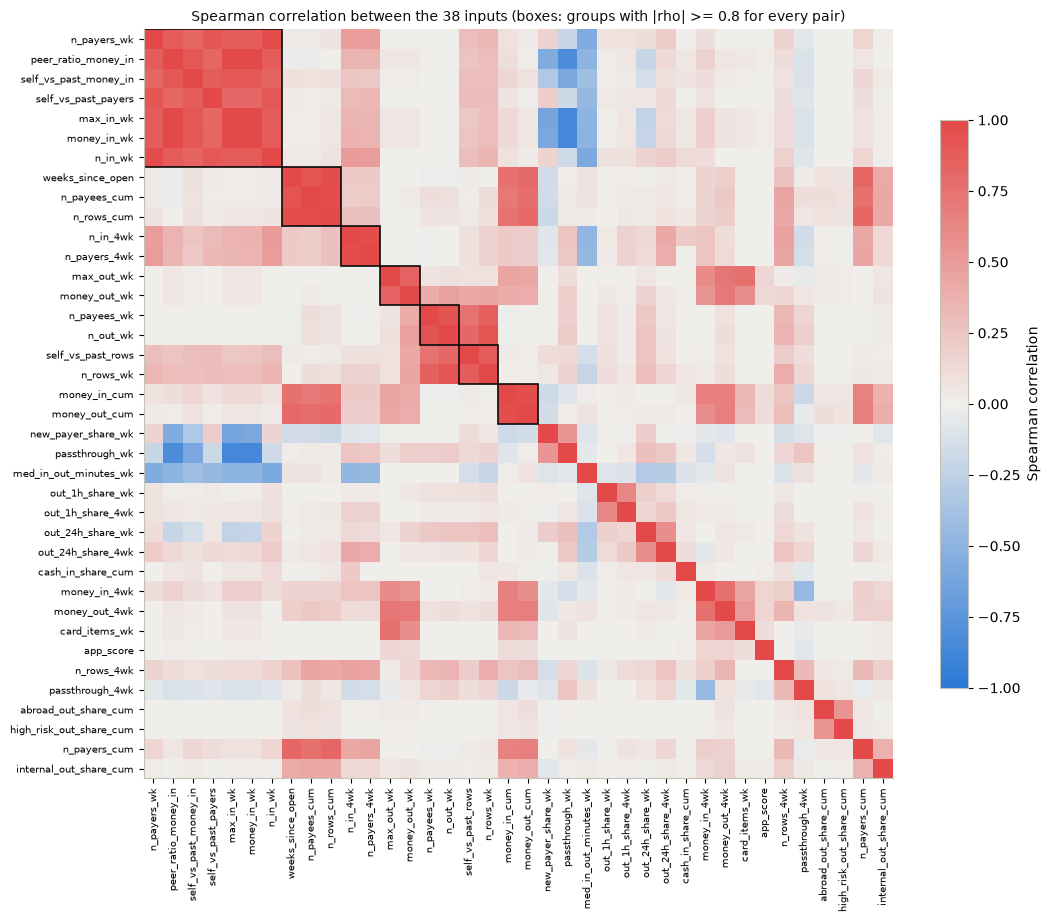

In [4]:
rho, cl = fs.spearman_clusters(df, COLS, threshold=CLUSTER_AT, seed=SEED)
for t in (0.7, 0.8, 0.9):
    c = fs.spearman_clusters(df, COLS, threshold=t, seed=SEED)[1]
    sizes = c.value_counts()
    print(f"|rho| >= {t}: {int((sizes > 1).sum())} groups of near-duplicates holding {int(sizes[sizes > 1].sum())} "
          f"features; {int((sizes == 1).sum())} features stand alone")

groups_multi = {}
for k, members in cl.groupby(cl).groups.items():
    members = list(members)
    if len(members) > 1:
        groups_multi[f"C{k}"] = members
groups_tab = pd.DataFrame({
    "members": [", ".join(m) for m in groups_multi.values()],
    "n": [len(m) for m in groups_multi.values()],
    "min_abs_rho": [rho.loc[m, m].abs().to_numpy()[np.triu_indices(len(m), 1)].min() for m in groups_multi.values()],
}, index=list(groups_multi))
show(groups_tab.round(3))

# heatmap, features ordered by group (near-duplicates sit together), then family
order = sorted(COLS, key=lambda c: (-(cl == cl[c]).sum(), cl[c], fs.FAMILY_OF[c], c))
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(rho.loc[order, order].to_numpy(), cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order)), order, fontsize=7)
ax.grid(False)
pos = {c: i for i, c in enumerate(order)}
for m in groups_multi.values():                    # outline each near-duplicate group
    idx = sorted(pos[c] for c in m)
    ax.add_patch(plt.Rectangle((idx[0] - 0.5, idx[0] - 0.5), len(idx), len(idx), fill=False, ec=INK, lw=1.2))
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title(f"Spearman correlation between the 38 inputs (boxes: groups with |rho| >= {CLUSTER_AT} for every pair)",
             fontsize=10)
fig.tight_layout()
fig.savefig(REPORT / "01_spearman_heatmap.png", dpi=130)
plt.show() if "ipykernel" in sys.modules else plt.close(fig)

## 4. What the model relies on

For each fold the tuned model is refitted exactly as in the feature lab (LightGBM defaults, balanced classes, seed 42,
deterministic), then its validation month is scored again with one input **shuffled** (its values moved to random
other rows), three times each. The fall in weekly recall is that input's **permutation importance**: how much the
model loses when the input carries no information.

Shuffling one member of a near-duplicate group understates its value, because the model can lean on the other members.
So whole groups from section 3, and whole families, are also shuffled together.

Two cheaper views are kept beside it for comparison: **gain** (how much each input improved the trees' splits while
training; known to favour continuous inputs) and **mean |SHAP|** (LightGBM's own per-row contributions, on all mule
rows plus 50,000 normal rows of the validation month; it also shows the direction of each effect).

This section takes the longest (on the full dataset roughly half an hour).

In [5]:
def measure(valid, s):
    return lab.weekly_recall(lab.weekly_top1(valid, s))

GROUPS = ({c: [c] for c in COLS} | groups_multi
          | {f"family {f}": c for f, c in fs.FAMILIES.items() if len(c) > 1})
perm, gains, shaps = [], [], []
for f, (train_m, valid_m) in enumerate(FOLDS, start=1):
    t = time.time()
    df["app_score"] = df["account_id"].map(scores[f])
    train, valid = df[df["open_month"].isin(train_m)], df[df["open_month"] == valid_m]
    model = lgb.LGBMClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1,
                               deterministic=True, force_row_wise=True)
    model.fit(train[COLS], train["mule_by_day"])
    g = model.booster_.feature_importance("gain")
    gains.append(pd.DataFrame({"feature": COLS, "gain_share": g / g.sum(), "fold": f}))
    p = fs.permutation_drop(model, valid, COLS, GROUPS, measure, repeats=REPEATS, seed=SEED + f)
    perm.append(p.assign(fold=f))
    rows = pd.concat([valid[valid["mule_by_day"] == 1],
                      valid[valid["mule_by_day"] == 0].sample(min(50_000, int((valid["mule_by_day"] == 0).sum())),
                                                              random_state=SEED)])
    shaps.append(fs.mean_abs_contrib(model, rows[COLS]).assign(fold=f))
    print(f"fold {f} (train {train_m} -> valid {valid_m}): weekly recall {p['base'].iloc[0]:.3f}, "
          f"{len(GROUPS)} groups x {REPEATS} shuffles ({time.time() - t:.0f}s)")
perm, gains, shaps = (pd.concat(x, ignore_index=True) for x in (perm, gains, shaps))

fold 1 (train (0, 1) -> valid 2): weekly recall 0.321, 52 groups x 3 shuffles (160s)


fold 2 (train (0, 1, 2) -> valid 3): weekly recall 0.312, 52 groups x 3 shuffles (158s)


fold 3 (train (0, 1, 2, 3) -> valid 4): weekly recall 0.347, 52 groups x 3 shuffles (144s)


## 5. Summary

Per input: the mean fall in weekly recall over the three folds (each fold's three shuffles averaged first), how many
folds fell, and the same for its near-duplicate group. Provisional labels (thresholds are assumptions, stated in §0):

| label | meaning |
|---|---|
| **needed** | shuffling it alone costs ≥ 0.5 points of weekly recall in all 3 folds |
| **covered by a near-copy** | alone it costs little, but its group of near-duplicates is needed: keep one or two members |
| **mixed** | costs ≥ 0.5 points on average, but not in every fold: unclear, kept out of the drop trials |
| **weak** | costs less than 0.5 points on average and its group is not needed: a candidate to drop, confirmed in §6 |

These labels are evidence, not decisions. A "weak" feature may still help real-customer mules or a few early weeks,
which the refit trials report separately.

,family,screen_auc,screen_signal,all_weeks_auc,near_copy_group,perm_drop,folds_down,group_drop,gain_share,mean_abs_shap,direction,label
feature,,,,,,,,,,,,
out_1h_share_4wk,window_4wk,0.9590,True,0.6292,,0.1176,3,NaN,0.0908,0.0764,0.3040,needed
app_score,application,0.8016,True,0.7997,,0.0944,3,NaN,0.5204,0.9477,0.6864,needed
n_payers_cum,counterparties,0.8285,True,0.5833,,0.0568,3,NaN,0.0523,0.1967,0.6368,needed
money_in_4wk,window_4wk,0.8686,True,0.6508,,0.0259,2,NaN,0.0688,0.2345,-0.0538,mixed
weeks_since_open,clock,0.5000,False,0.4797,C23,0.0248,3,0.0470,0.0108,0.3891,-0.9079,needed
internal_out_share_cum,mix,0.6570,True,0.5563,,0.0159,3,NaN,0.0344,0.1948,0.0870,needed
out_24h_share_4wk,window_4wk,0.9482,True,0.6081,,0.0138,3,NaN,0.0167,0.1391,-0.1415,needed
n_rows_4wk,window_4wk,0.9180,True,0.6085,,0.0116,2,NaN,0.0099,0.0707,0.2997,mixed
money_in_cum,volume_cum,0.7356,True,0.5882,C22,0.0105,3,0.0157,0.0109,0.1141,0.4844,needed


label
weak                      15
needed                    13
covered by a near-copy     8
mixed                      2


,n,perm_drop,folds_down,needed_members,family_needed
family,,,,,
window_4wk,8,0.1269,3,2,True
application,1,0.0944,3,1,True
counterparties,5,0.0589,3,2,True
clock,1,0.0248,3,1,True
mix,4,0.0184,3,1,True
volume_cum,3,0.0175,3,2,True
volume_wk,8,0.0145,3,2,True
flow,4,0.0110,3,1,True
self_vs_past,3,0.0073,3,1,True


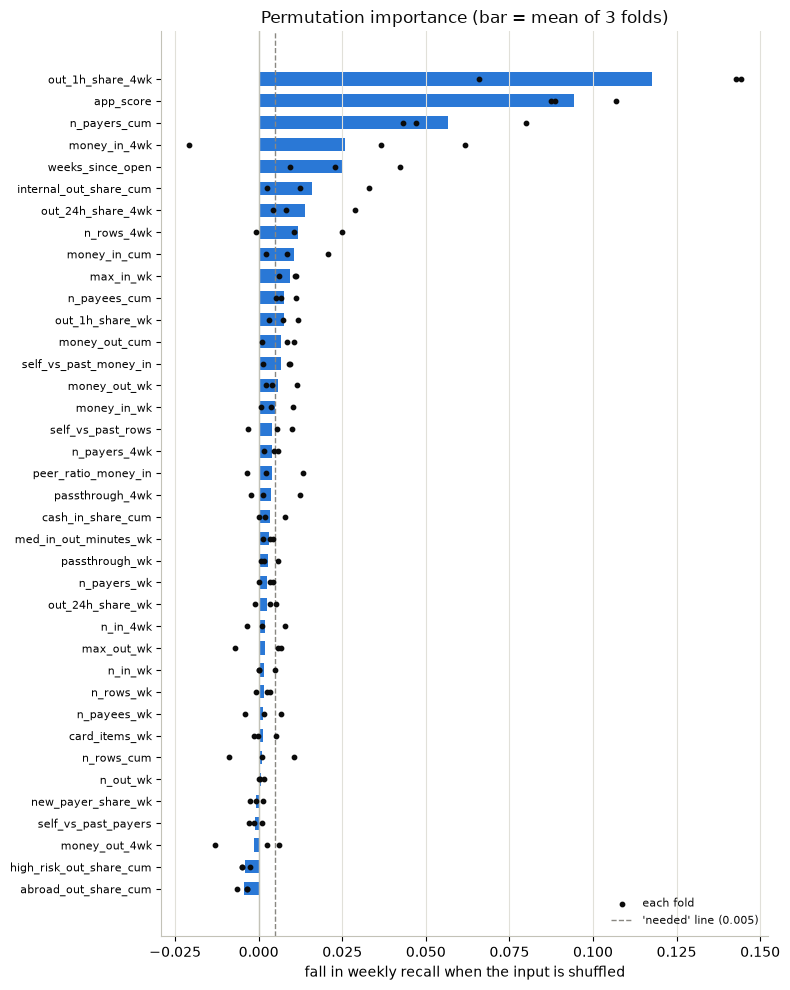

In [6]:
per_fold = perm.groupby(["group", "fold"])["drop"].mean().unstack("fold")
stat = pd.DataFrame({"drop": per_fold.mean(axis=1), "folds_down": (per_fold > 0).sum(axis=1),
                     "min_fold": per_fold.min(axis=1)})
is_needed = lambda g: bool(stat.loc[g, "folds_down"] == len(FOLDS) and stat.loc[g, "drop"] >= NEEDED)
group_of = {c: k for k, m in groups_multi.items() for c in m}

summary = inv[["family", "screen_auc", "screen_signal", "all_weeks_auc"]].copy()
summary["near_copy_group"] = [group_of.get(c, "") for c in COLS]
summary["perm_drop"] = stat.loc[COLS, "drop"].to_numpy()
summary["folds_down"] = stat.loc[COLS, "folds_down"].astype(int).to_numpy()
summary["group_drop"] = [stat.loc[group_of[c], "drop"] if c in group_of else np.nan for c in COLS]
summary["gain_share"] = gains.groupby("feature")["gain_share"].mean().loc[COLS].to_numpy()
summary["mean_abs_shap"] = shaps.groupby("feature")["mean_abs_shap"].mean().loc[COLS].to_numpy()
summary["direction"] = shaps.groupby("feature")["direction"].mean().loc[COLS].to_numpy()
summary["label"] = ["needed" if is_needed(c) else
                    "covered by a near-copy" if c in group_of and is_needed(group_of[c]) else
                    "mixed" if stat.loc[c, "drop"] >= NEEDED else "weak" for c in COLS]
summary = summary.sort_values("perm_drop", ascending=False)
show(summary.round(4))
print(summary["label"].value_counts().to_string())

fam = pd.DataFrame({
    "n": [len(c) for c in fs.FAMILIES.values()],
    "perm_drop": [stat.loc[f"family {f}" if len(c) > 1 else c[0], "drop"] for f, c in fs.FAMILIES.items()],
    "folds_down": [int(stat.loc[f"family {f}" if len(c) > 1 else c[0], "folds_down"]) for f, c in fs.FAMILIES.items()],
    "needed_members": [int((summary.loc[c, "label"] == "needed").sum()) for c in fs.FAMILIES.values()],
}, index=pd.Index(list(fs.FAMILIES), name="family"))
fam["family_needed"] = [is_needed(f"family {f}" if len(c) > 1 else c[0]) for f, c in fs.FAMILIES.items()]
show(fam.sort_values("perm_drop", ascending=False).round(4))

# figure: permutation importance per input, bar = mean of 3 folds, dots = each fold
pf = per_fold.loc[summary.index[::-1]]
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(range(len(pf)), pf.mean(axis=1), color=BLUE, height=0.6)
for j in pf.columns:
    ax.scatter(pf[j], range(len(pf)), color=INK, s=10, zorder=3, label="each fold" if j == pf.columns[0] else None)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.axvline(NEEDED, color=MUTED, lw=1, ls="--", label=f"'needed' line ({NEEDED})")
ax.set_yticks(range(len(pf)), pf.index, fontsize=8)
ax.grid(axis="y", visible=False)
ax.set(xlabel="fall in weekly recall when the input is shuffled", title="Permutation importance (bar = mean of 3 folds)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(REPORT / "02_permutation_importance.png", dpi=130)
plt.show() if "ipykernel" in sys.modules else plt.close(fig)

## 6. Next step and report

Shuffling one input at a time can miss inputs that only matter *together*, so the labels are confirmed by refitting
the model without them (`python -m models.feature_lab --drop ... --together`). It judges the smaller model on all three
folds with the team's rule ('no clear change' = they can go without a measurable loss) and also reports real-customer
mules and catching within two weeks of the start. Two trials, from cautious to bold:

1. **drop the weak inputs**;
2. **also drop the spare near-copies**: in a group of near-duplicates with a needed member, the members labelled
   "covered"; in a group without one, every member except the one whose shuffle costs most.

"Mixed" inputs stay in both. Every trial lands in the feature lab's ledger, so the number of looks is on record.

In [7]:
weak = list(summary.index[summary["label"] == "weak"])
spare = []
for k, m in groups_multi.items():
    lab_m = summary.loc[m, "label"]
    covered = list(lab_m.index[lab_m == "covered by a near-copy"])
    if not (lab_m == "needed").any() and covered:     # keep the strongest member of a group with no needed member
        covered.remove(summary.loc[covered, "perm_drop"].idxmax())
    spare += covered
trials = {f"drop-weak-{RUN}": weak, f"drop-weak-and-copies-{RUN}": weak + spare}
cmds = [f"python -m models.feature_lab --out {OUT} --drop {' '.join(cols)} --together --name {name}"
        for name, cols in trials.items() if cols]
print(f"weak ({len(weak)}): {', '.join(weak) or 'none'}")
print(f"spare near-copies ({len(spare)}): {', '.join(spare) or 'none'}")
print(f"inputs left after trial 2: {len(COLS) - len(weak) - len(spare)} of {len(COLS)}")
print("\n".join(cmds) or "(nothing to drop)")

inv.to_csv(REPORT / "inventory.csv")
rho.to_csv(REPORT / "spearman.csv")
groups_tab.to_csv(REPORT / "near_copy_groups.csv")
perm.to_csv(REPORT / "permutation.csv", index=False)
summary.to_csv(REPORT / "summary.csv")
fam.to_csv(REPORT / "families.csv")
lines = [
    f"# Feature selection, steps 1-3 ({RUN})", "",
    f"Data `{OUT}`, training months 0-4, weeks 0-26, 3 folds, seed {SEED}, lightgbm {lgb.__version__}. "
    f"Executed copy: `07_feature_selection.ipynb`. Thresholds (assumptions): near-duplicates |rho| >= {CLUSTER_AT}; "
    f"'needed' = weekly recall falls by >= {NEEDED} in all 3 folds when shuffled ({REPEATS} shuffles per fold).", "",
    "## Per input", "", summary.round(4).to_markdown(), "",
    "## Per family", "", fam.round(4).to_markdown(), "",
    f"## Near-duplicate groups (|rho| >= {CLUSTER_AT} for every pair)", "", groups_tab.round(3).to_markdown(), "",
    "![heatmap](01_spearman_heatmap.png)", "", "![permutation](02_permutation_importance.png)", "",
    "## Next step: confirm by refitting without them", "",
    f"- weak ({len(weak)}): {', '.join(weak) or 'none'}",
    f"- spare near-copies ({len(spare)}): {', '.join(spare) or 'none'}",
    f"- inputs left after trial 2: {len(COLS) - len(weak) - len(spare)} of {len(COLS)}", "",
    *[f"`{c}`" + "\n" for c in cmds],
    "Labels are evidence, not decisions: the model's inputs change only by team decision after the "
    "refit trials above.", ""]
(REPORT / "report.md").write_text("\n".join(lines), encoding="utf-8")
print(f"-> {REPORT}  ({time.time() - T0:.0f}s total)")

weak (15): n_payers_4wk, passthrough_4wk, cash_in_share_cum, med_in_out_minutes_wk, passthrough_wk, out_24h_share_wk, n_in_4wk, max_out_wk, n_payees_wk, card_items_wk, n_out_wk, new_payer_share_wk, money_out_4wk, high_risk_out_share_cum, abroad_out_share_cum
spare near-copies (7): n_in_wk, money_in_wk, n_payers_wk, self_vs_past_payers, peer_ratio_money_in, n_rows_wk, n_rows_cum
inputs left after trial 2: 16 of 38
python -m models.feature_lab --out data/v1 --drop n_payers_4wk passthrough_4wk cash_in_share_cum med_in_out_minutes_wk passthrough_wk out_24h_share_wk n_in_4wk max_out_wk n_payees_wk card_items_wk n_out_wk new_payer_share_wk money_out_4wk high_risk_out_share_cum abroad_out_share_cum --together --name drop-weak-v1
python -m models.feature_lab --out data/v1 --drop n_payers_4wk passthrough_4wk cash_in_share_cum med_in_out_minutes_wk passthrough_wk out_24h_share_wk n_in_4wk max_out_wk n_payees_wk card_items_wk n_out_wk new_payer_share_wk money_out_4wk high_risk_out_share_cum abroa